# Разделение данных для обучения и тестирования, перекрестная валидация и линейная регрессия

# Цели обучения

- Объяснить разницу между переобучением и недообучением модели
- Описать компромисс между систематической ошибкой и дисперсией
- Определить оптимальное разделение наборов данных для обучения и тестирования, провести перекрестную валидацию и проанализировать взаимосвязь между сложностью модели и погрешностью
- Применить модель линейной регрессии для обучения с учителем
- Применить расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения

## Введение

Мы будем работать с набором данных, основанным на [ценах на жилье в Эймсе, штат Айова](https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Он был составлен для учебных целей в качестве обновленной и расширенной альтернативы хорошо известному набору данных «Boston Housing». В этой версии набора данных для удобства были восстановлены некоторые пропущенные значения.

Количество признаков довольно велико, поэтому они описаны в таблице ниже.

### Прогнозируемая переменная

* SalePrice: цена продажи недвижимости в долларах.


### Features

<table>
  <tbody>    
    <tr valign="top">
      <td valign="top">
        <ul>
          <li>MoSold: Month Sold</li>
          <li>YrSold: Year Sold</li><br>
          
          <li>SaleType: Type of sale</li>
          <li>SaleCondition: Condition of sale</li><br>

          <li>MSSubClass: The building class</li>
          <li>MSZoning: The general zoning classification</li><br>

          <li>Neighborhood: Physical locations within Ames city limits</li>
          <li>Street: Type of road access</li>
          <li>Alley: Type of alley access</li><br>

          <li>LotArea: Lot size in square feet</li>
          <li>LotConfig: Lot configuration</li>
          <li>LotFrontage: Linear feet of street connected to property</li>
          <li>LotShape: General shape of property</li><br>

          <li>LandSlope: Slope of property</li>
          <li>LandContour: Flatness of the property</li><br>

          <li>YearBuilt: Original construction date</li>
          <li>YearRemodAdd: Remodel date</li>
          <li>OverallQual: Overall material and finish quality</li>
          <li>OverallCond: Overall condition rating</li><br>

          <li>Utilities: Type of utilities available</li>
          <li>Foundation: Type of foundation</li>
          <li>Functional: Home functionality rating</li><br>

          <li>BldgType: Type of dwelling</li>
          <li>HouseStyle: Style of dwelling</li><br>
          
          <li>1stFlrSF: First Floor square feet</li>
          <li>2ndFlrSF: Second floor square feet</li>
          <li>LowQualFinSF: Low quality finished square feet (all floors)</li>
          <li>GrLivArea: Above grade (ground) living area square feet</li>
          <li>TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)</li><br>

          <li>Condition1: Proximity to main road or railroad</li>
          <li>Condition2: Proximity to main road or railroad (if a second is present)</li><br>
          
          <li>RoofStyle: Type of roof</li>
          <li>RoofMatl: Roof material</li><br>

          <li>ExterQual: Exterior material quality</li>
          <li>ExterCond: Present condition of the material on the exterior</li>
          <li>Exterior1st: Exterior covering on house</li>
          <li>Exterior2nd: Exterior covering on house (if more than one material)</li><br><br>
          
        </ul>
      </td>
      
      <td valign="top">
        <ul>
          <li>MasVnrType: Masonry veneer type</li>
          <li>MasVnrArea: Masonry veneer area in square feet</li><br>
          
          <li>WoodDeckSF: Wood deck area in square feet</li>
          <li>OpenPorchSF: Open porch area in square feet</li>
          <li>EnclosedPorch: Enclosed porch area in square feet</li>
          <li>3SsnPorch: Three season porch area in square feet</li>
          <li>ScreenPorch: Screen porch area in square feet</li><br>

          <li>PoolArea: Pool area in square feet</li>
          <li>PoolQC: Pool quality</li>
          <li>Fence: Fence quality</li>
          <li>PavedDrive: Paved driveway</li><br>

          <li>GarageType: Garage location</li>
          <li>GarageYrBlt: Year garage was built</li>
          <li>GarageFinish: Interior finish of the garage</li>
          <li>GarageCars: Size of garage in car capacity</li>
          <li>GarageArea: Size of garage in square feet</li>
          <li>GarageQual: Garage quality</li>
          <li>GarageCond: Garage condition</li><br>

          <li>Heating: Type of heating</li>
          <li>HeatingQC: Heating quality and condition</li>
          <li>CentralAir: Central air conditioning</li>
          <li>Electrical: Electrical system</li><br>
          
          <li>FullBath: Full bathrooms above grade</li>
          <li>HalfBath: Half baths above grade</li><br>
          
          <li>BedroomAbvGr: Number of bedrooms above basement level</li><br>
          
          <li>KitchenAbvGr: Number of kitchens</li>
          <li>KitchenQual: Kitchen quality</li><br>
          
          <li>Fireplaces: Number of fireplaces</li>
          <li>FireplaceQu: Fireplace quality</li><br>
          
          <li>MiscFeature: Miscellaneous feature not covered in other categories</li>
          <li>MiscVal: Value of miscellaneous feature</li><br>
          
          <li>BsmtQual: Height of the basement</li>
          <li>BsmtCond: General condition of the basement</li>
          <li>BsmtExposure: Walkout or garden level basement walls</li>
          <li>BsmtFinType1: Quality of basement finished area</li>
          <li>BsmtFinSF1: Type 1 finished square feet</li>
          <li>BsmtFinType2: Quality of second finished area (if present)</li>
          <li>BsmtFinSF2: Type 2 finished square feet</li>
          <li>BsmtUnfSF: Unfinished square feet of basement area</li>
          <li>BsmtFullBath: Basement full bathrooms</li>
          <li>BsmtHalfBath: Basement half bathrooms</li>
          <li>TotalBsmtSF: Total square feet of basement area</li>
        </ul>
      </td>
    </tr>
    
  </tbody>
</table>

## Что мы делаем в этой работе

Задача - предсказать цену дома (`SalePrice`) по его характеристикам с помощью обычной линейной регрессии. Главная идея лабораторной: модель нельзя оценивать на тех же данных, на которых она училась, поэтому выборку делим на обучающую и тестовую части и смотрим, насколько ошибки на них отличаются. Если на обучении ошибка маленькая, а на тесте большая - это переобучение.

Данные берём из файла `train.csv` (тот же набор Ames Housing с Kaggle, 1460 домов).

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler

# расширение Intel для scikit-learn (если оно установлено, ускоряет расчёты)
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex не установлен, используем обычный scikit-learn')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные с помощью Pandas и проанализируйте их структуру. В наборе данных 79 столбцов с признаками, а также предиктор - цена продажи (`SalePrice`).
* В наборе данных присутствуют три различных типа: целые числа (`int64`), числа с плавающей запятой (`float64`) и строки (`object`, категориальные значения). Определите, сколько значений каждого типа данных присутствует в наборе.

In [5]:
filepath = 'data/train.csv'          # путь к файлу с данными
data = pd.read_csv(filepath)

print(data.shape)
data.head(3)

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


В файле есть служебный столбец `Id` - просто номер строки, предсказывать по нему цену бессмысленно, поэтому убираем его. После этого должно остаться 79 признаков и целевая переменная `SalePrice`.

In [6]:
data = data.drop('Id', axis=1)
print(data.shape)

(1460, 80)


In [7]:
# сколько столбцов каждого типа
data.dtypes.astype(str).value_counts()

str        43
int64      34
float64     3
Name: count, dtype: int64

**Вывод.** Типы столбцов: целочисленные (`int64`), с плавающей запятой (`float64`) и строковые (в выводе они могут называться `object` или `str` - зависит от версии pandas). Строковых признаков больше всего (43), и именно с ними придётся работать отдельно, потому что линейная регрессия умеет работать только с числами.

Линейная регрессия также не умеет работать с пропусками (`NaN`), поэтому посмотрим, где они есть.

In [8]:
missing = data.isna().sum()
missing[missing > 0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Судя по `data_description.txt`, у большинства категориальных признаков `NaN` означает не «данные потеряны», а «такого объекта нет» (нет бассейна, гаража, подвала, камина и т.д.). Поэтому для строковых столбцов пропуск заменяем отдельной категорией `'None'`. Единственное исключение - `Electrical`: там пропуск всего один, и его логичнее заменить самым частым значением.

Для числовых столбцов: у `LotFrontage` пропуски заполняем медианой, у `MasVnrArea` - нулём (облицовки нет), а у `GarageYrBlt` - годом постройки дома (гаража нет, берём ближайшее по смыслу значение).

In [9]:
str_cols = data.select_dtypes(exclude='number').columns

# Electrical: один пропуск -> самое частое значение
data['Electrical'] = data['Electrical'].fillna(data['Electrical'].mode()[0])

# остальные строковые: NaN значит «нет такого объекта»
data[str_cols] = data[str_cols].fillna('None')

# числовые
data['LotFrontage'] = data['LotFrontage'].fillna(data['LotFrontage'].median())
data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
data['GarageYrBlt'] = data['GarageYrBlt'].fillna(data['YearBuilt'])

print('Осталось пропусков:', data.isna().sum().sum())

Осталось пропусков: 0


## Вопрос 2

Как обсуждалось на лекции, одной из основных сложностей, особенно при работе с данными, содержащими большое количество столбцов, является обеспечение правильного кодирования каждого столбца.

Это особенно актуально в случае столбцов данных, содержащих упорядоченные категориальные переменные (порядковые) по сравнению с неупорядоченными категориальными переменными. Неупорядоченные категориальные переменные следует кодировать методом «one-hot», однако это может значительно увеличить количество признаков и привести к появлению признаков, сильно коррелирующих друг с другом.

Определите, какое общее количество признаков будет присутствовать по сравнению с тем, что существует в настоящее время, если все строковые (объектные) признаки будут закодированы по методу «one-hot». Напомним, что общее количество столбцов, закодированных по методу «one-hot», равно `n-1`, где `n` - количество категорий.

In [10]:
# строковые (категориальные) столбцы
categorical_cols = data.select_dtypes(exclude='number').columns
print('Категориальных столбцов:', len(categorical_cols))

Категориальных столбцов: 43


In [11]:
# число уникальных категорий в каждом столбце
n_categories = data[categorical_cols].nunique().sort_values(ascending=False)
print(n_categories.head(8))

# если категория всего одна, кодировать нечего
n_categories = n_categories[n_categories > 1]

# новых столбцов на каждый признак - на один меньше, чем категорий
extra_cols = (n_categories - 1).sum()
print('\nДополнительных столбцов после one-hot:', extra_cols)
print('Признаков сейчас (без SalePrice):', data.shape[1] - 1)
print('Признаков после кодирования:', data.shape[1] - 1 + extra_cols)

Neighborhood    25
Exterior2nd     16
Exterior1st     15
Condition1       9
SaleType         9
HouseStyle       8
RoofMatl         8
Condition2       8
dtype: int64

Дополнительных столбцов после one-hot: 223
Признаков сейчас (без SalePrice): 79
Признаков после кодирования: 302


**Вывод.** Каждый категориальный признак с `n` категориями превращается в `n` столбцов из нулей и единиц, а сам исходный столбец удаляется - итого чистый прирост `n-1` столбец на признак. В сумме получается 223 дополнительных столбца, то есть признаков становится в несколько раз больше (примерно 79 → 302). Это много для 1460 строк: растёт риск переобучения, а новые столбцы к тому же сильно связаны друг с другом (если известно, что дом не `Pave`, то он точно `Grvl`).

## Вопрос 3

Давайте создадим новый набор данных, в котором все вышеперечисленные категориальные признаки будут закодированы по методу «one-hot». Мы можем провести обучение на этих данных и посмотреть, как это повлияет на результаты.

* Используем метод `.copy()` датафрейма, чтобы создать полностью отдельную копию датафрейма для кодирования по принципу «one-hot».
* В этом новом датафрейме закодируем по принципу «one-hot» каждый из соответствующих столбцов и добавим его обратно в датафрейм. Обязательно удалите исходный столбец.
* Для данных, которые не кодируются по принципу «one-hot», удалите столбцы, представляющие собой строковые категориальные переменные.

На первом этапе, при числовом кодировании строковых категориальных переменных, можно использовать либо `LabelEncoder`, либо `DictVectorizer` из Scikit-learn. Однако первый вариант, вероятно, проще, поскольку не требует указания числового значения для каждой категории, а мы в любом случае будем применять кодирование «one-hot» ко всем числовым значениям. (Можете ли вы придумать ситуацию, в которой предпочтительнее использовать `DictVectorizer`?)

In [12]:
# отдельная копия, чтобы исходные данные не испортить
data_ohc = data.copy()

# one-hot кодирование: исходные строковые столбцы заменяются на столбцы 0/1
data_ohc = pd.get_dummies(data_ohc, columns=list(categorical_cols), dtype=float)

# в другом наборе просто убираем все строковые столбцы
data_num = data.drop(columns=categorical_cols)

print('С one-hot:', data_ohc.shape)
print('Без кодирования (только числа):', data_num.shape)

С one-hot: (1460, 303)
Без кодирования (только числа): (1460, 37)


In [13]:
# разница в числе столбцов должна совпасть с расчётом из вопроса 2
data_ohc.shape[1] - data.shape[1]

223

**Вывод.** Получилось два набора: `data_ohc` (числа + one-hot столбцы, 302 признака плюс цена) и `data_num` (только 36 числовых признаков плюс цена). Разница в 223 столбца совпадает с расчётом из вопроса 2 - значит, кодирование выполнено правильно.

## Вопрос 4

* Разделите оба набора данных на обучающую и тестовую части. Чтобы обеспечить одинаковое разделение данных, используйте одинаковый параметр `random_state` при разделении каждого из наборов.
* Для каждого набора данных постройте базовую линейную регрессионную модель на обучающих данных.
* Рассчитайте среднеквадратичную ошибку для соответствующих моделей как на обучающем, так и на тестовом наборах данных. Какая модель дает меньшую ошибку на тестовых данных и почему?

In [14]:
y_col = 'SalePrice'

def make_split(df):
    X = df.drop(columns=y_col)
    y = df[y_col]
    return train_test_split(X, y, test_size=0.3, random_state=42)

# одинаковые test_size и random_state -> одинаковые строки попадают в train/test
X_train, X_test, y_train, y_test = make_split(data_num)
X_train_ohc, X_test_ohc, y_train_ohc, y_test_ohc = make_split(data_ohc)

In [15]:
# проверка: индексы строк в обоих разбиениях совпадают
bool((X_train_ohc.index == X_train.index).all())

True

Разбиение 70/30: на 70% данных модель учится, а на оставшихся 30% (которые она не видела) мы честно проверяем качество. Одинаковый `random_state` нужен, чтобы оба набора делились по одним и тем же домам, иначе сравнение моделей было бы некорректным.

Качество измеряем среднеквадратичной ошибкой (MSE): чем она меньше, тем точнее модель. Дополнительно посчитаем RMSE (корень из MSE) - она в тех же единицах, что и цена, то есть в долларах, поэтому её проще интерпретировать.

In [16]:
def fit_and_score(Xtr, ytr, Xte, yte, label):
    model = LinearRegression().fit(Xtr, ytr)
    mse_train = mean_squared_error(ytr, model.predict(Xtr))
    mse_test = mean_squared_error(yte, model.predict(Xte))
    return model, pd.Series({'train': mse_train, 'test': mse_test}, name=label)

model_num, res_num = fit_and_score(X_train, y_train, X_test, y_test, 'без кодирования')
model_ohc, res_ohc = fit_and_score(X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc, 'one-hot')

error_df = pd.concat([res_num, res_ohc], axis=1)
error_df

,без кодирования,one-hot
train,1.197764e+09,3.565767e+08
test,1.243828e+09,6.336075e+09


In [17]:
# RMSE в долларах
np.sqrt(error_df).round(0)

,без кодирования,one-hot
train,34609.0,18883.0
test,35268.0,79599.0


**Вывод.** Без кодирования ошибка на обучении и на тесте примерно одинаковая (около 1.2·10⁹), то есть модель простая и стабильная, хотя и не очень точная (RMSE порядка 35 тыс. долларов).

С one-hot кодированием на обучающих данных ошибка гораздо меньше (около 3.6·10⁸), потому что у модели появилось много новых признаков и она может подогнаться под обучающую выборку почти идеально. Но на тесте ошибка выросла примерно до 6.3·10⁹ - в несколько раз больше, чем у простой модели. Это классическое **переобучение**: модель «запомнила» обучающие дома, включая случайные особенности, и плохо обобщает на новые.

Поэтому **меньшую ошибку на тестовых данных даёт модель без one-hot кодирования** - парадоксально, но более простая модель оказалась лучше. Борьбу с переобучением (регуляризацию) будем изучать дальше.

## Вопрос 5

Для каждого из наборов данных (с кодировкой «one-hot» и без неё):

* Отрегулируйте масштаб всех значений, не кодированных по методу «one-hot», с помощью одного из следующих методов: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`.
* Сравните ошибку, рассчитанную на тестовых наборах.

Обязательно рассчитайте асимметрию (чтобы определить, следует ли проводить преобразование) и подберите масштабатор *ТОЛЬКО* на обучающих данных, но затем примените его одинаково как к обучающим, так и к тестовым данным.

Асимметрия (skewness) показывает, насколько распределение признака «перекошено». Если она сильно отличается от нуля (обычно берут порог |skew| > 1), у признака длинный «хвост» из очень больших значений, и иногда помогает логарифмирование. Считаем её только по обучающей выборке.

In [18]:
# числовые признаки, которые будем масштабировать (one-hot столбцы не трогаем)
num_features = X_train.columns

skewness = X_train[num_features].apply(lambda s: skew(s)).sort_values(ascending=False)
print(skewness.head(10))
print('\nПризнаков с |skew| > 1:', (skewness.abs() > 1).sum(), 'из', len(skewness))

MiscVal          16.768158
PoolArea         14.819804
LotArea          11.632698
3SsnPorch         9.843452
LowQualFinSF      9.087439
BsmtFinSF2        4.344517
ScreenPorch       4.135853
KitchenAbvGr      4.077858
BsmtHalfBath      3.925308
EnclosedPorch     3.275002
dtype: float64

Признаков с |skew| > 1: 19 из 36


Сильно скошенных признаков довольно много (например, `MiscVal`, `PoolArea`, `LotArea`) - у них большинство значений маленькие, а несколько домов имеют огромные значения. Проверим, поможет ли логарифмирование, чуть ниже.

Теперь масштабирование. Каждый скейлер подбираем (`fit`) **только на обучающих данных**, а к тесту применяем (`transform`) с теми же параметрами - иначе информация о тестовой выборке «просочится» в обучение.

In [19]:
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'MaxAbsScaler': MaxAbsScaler(),
}

splits = {
    'без кодирования': (X_train, y_train, X_test, y_test),
    'one-hot': (X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc),
}

rows = {}
for enc_name, (Xtr, ytr, Xte, yte) in splits.items():
    for sc_name, scaler in scalers.items():
        Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
        # масштабируем только исходные числовые столбцы
        Xtr_s[num_features] = scaler.fit_transform(Xtr[num_features])
        Xte_s[num_features] = scaler.transform(Xte[num_features])

        lr = LinearRegression().fit(Xtr_s, ytr)
        rows[(enc_name, sc_name)] = mean_squared_error(yte, lr.predict(Xte_s))

scaling_errors = pd.Series(rows, name='MSE на тесте')
scaling_errors.to_frame()

MSE на тесте
без кодирования StandardScaler  1.243828e+09
                MinMaxScaler    1.243828e+09
                MaxAbsScaler    1.243828e+09
one-hot         StandardScaler  6.326694e+09
                MinMaxScaler    6.333396e+09
                MaxAbsScaler    6.336287e+09

**Вывод.** Масштабирование практически не изменило ошибку: для каждого набора результаты всех трёх скейлеров совпадают (с точностью до погрешностей вычислений) и равны ошибкам из вопроса 4. Это ожидаемо: обычная линейная регрессия без регуляризации не чувствительна к масштабу признаков - при изменении масштаба просто пропорционально меняются коэффициенты, а предсказания остаются теми же. Масштабирование станет важным позже, когда появится регуляризация (Ridge, Lasso) и градиентные методы.

По-прежнему модель без one-hot кодирования показывает меньшую ошибку на тесте, чем модель с one-hot.

Дополнительно проверим, нужна ли логарифмическая трансформация для сильно скошенных признаков (|skew| > 1). Колонки для преобразования выбираем по обучающей выборке.

In [20]:
skewed = [c for c in skewness.index
          if abs(skewness[c]) > 1 and (X_train[c] >= 0).all()]

for enc_name, (Xtr, ytr, Xte, yte) in splits.items():
    Xtr_l, Xte_l = Xtr.copy(), Xte.copy()
    Xtr_l[skewed] = np.log1p(Xtr_l[skewed])
    Xte_l[skewed] = np.log1p(Xte_l[skewed])

    sc = StandardScaler()
    Xtr_l[num_features] = sc.fit_transform(Xtr_l[num_features])
    Xte_l[num_features] = sc.transform(Xte_l[num_features])

    lr = LinearRegression().fit(Xtr_l, ytr)
    print(enc_name, '->', round(mean_squared_error(yte, lr.predict(Xte_l))))

без кодирования -> 1307316351
one-hot -> 48350020684


**Вывод.** Логарифмирование скошенных признаков ошибку не улучшило (без кодирования она стала чуть хуже - примерно 1.31·10⁹ против 1.24·10⁹, с one-hot - значительно хуже). Значит, в этой постановке преобразование не нужно, и для сравнения моделей достаточно обычного масштабирования.

## Вопрос 6

Постройте график, сравнивающий прогнозы и фактические данные для одной из моделей.

График «предсказание против факта»: каждая точка - один дом из тестовой выборки. Если бы модель была идеальной, все точки лежали бы на диагонали (красная линия). Чем дальше точки от неё, тем больше ошибка.

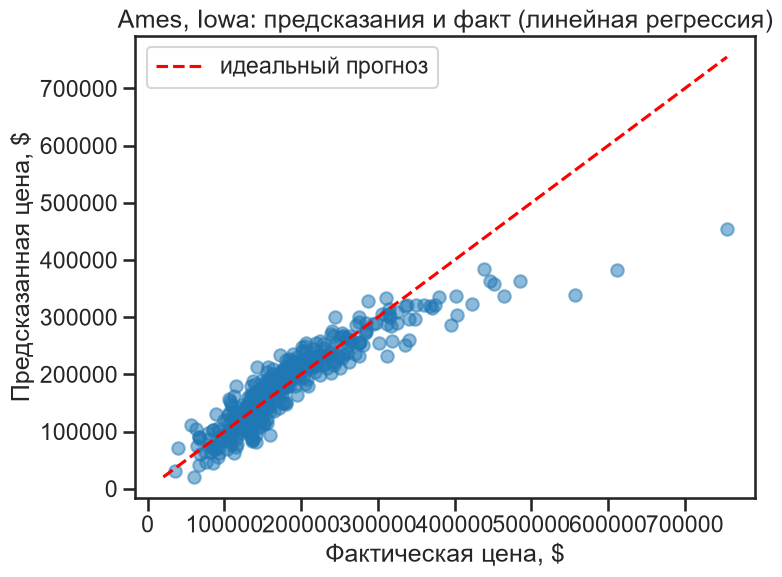

In [21]:
y_test_pred = model_num.predict(X_test)

sns.set_context('talk')
sns.set_style('ticks')

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_test_pred, alpha=0.5)

lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, color='red', linestyle='--', label='идеальный прогноз')

ax.set(xlabel='Фактическая цена, $',
       ylabel='Предсказанная цена, $',
       title='Ames, Iowa: предсказания и факт (линейная регрессия)')
ax.legend()
plt.show()

**Вывод.** Точки в основном группируются вдоль диагонали, то есть модель в целом улавливает зависимость цены от признаков. Но разброс заметный, а у дорогих домов (справа на графике) модель часто ошибается сильнее. Это типичное ограничение простой линейной модели: она описывает только линейные зависимости и не учитывает более сложные эффекты.

## Итоги

- Строковые признаки нельзя подавать в линейную регрессию напрямую; после one-hot кодирования признаков становится в несколько раз больше (79 → 302).
- Более сложная модель (с one-hot) почти идеально подгоняется под обучающие данные, но на тесте ошибается сильнее - это переобучение, а простая модель без кодирования обобщает лучше.
- Масштабирование не влияет на качество обычной линейной регрессии.
- Логарифмирование скошенных признаков здесь не помогло.
- Оценивать модель нужно на отложенной тестовой выборке, а разницу между ошибками на train и test использовать как индикатор переобучения.